# ETH Option Chain - Data Inventory

Full picture of what's available on Deribit for ETH options right now.

**Answers:**

1. How many expiries are listed?
2. How many contracts per expiry?
3. How far out does the chain go?
4. How many strikes per expiry?
5. What's the strike range (min-max)?
6. Which contracts are actually liquid (traded today)?
7. Which expiries have real OI vs dead listings?
8. Where is the liquidity concentrated?
9. Which contracts are tradeable for a buyer?
10. Summary of the entire chain

## Setup

In [1]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timezone
import time

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
pd.set_option('display.max_rows', 200)
plt.rcParams['figure.figsize'] = (13, 5)

DERIBIT = 'https://www.deribit.com/api/v2/public'
CURRENCY = 'ETH'
print('ready')

ready


## 1. Fetch the full ETH option chain

In [2]:
def fetch_chain(currency):
    r = requests.get(f'{DERIBIT}/get_book_summary_by_currency',
                     params={'currency': currency, 'kind': 'option'}, timeout=20)
    r.raise_for_status()
    return r.json()['result']


def parse_name(name):
    parts = name.split('-')
    if len(parts) != 4:
        return None
    try:
        _, exp, strike, kind = parts
        dt = datetime.strptime(exp, '%d%b%y').replace(tzinfo=timezone.utc, hour=8)
        return int(dt.timestamp() * 1000), float(strike), kind
    except (ValueError, IndexError):
        return None


raw = fetch_chain(CURRENCY)
now_ms = int(time.time() * 1000)

rows = []
for r in raw:
    p = parse_name(r['instrument_name'])
    if p is None:
        continue
    rows.append({
        'instrument': r['instrument_name'],
        'expiry': p[0],
        'expiry_dt': pd.to_datetime(p[0], unit='ms', utc=True).tz_convert(None),
        'strike': p[1],
        'kind': p[2],
        'days': (p[0] - now_ms) / 86_400_000,
        'mark': r.get('mark_price'),
        'bid': r.get('bid_price'),
        'ask': r.get('ask_price'),
        'iv': r.get('mark_iv'),
        'oi': r.get('open_interest') or 0,
        'volume': r.get('volume') or 0,
        'underlying': r.get('underlying_price'),
    })

df = pd.DataFrame(rows)
df['iv_dec'] = df['iv'] / 100.0
df['spread_pct'] = (df['ask'] - df['bid']) / ((df['ask'] + df['bid']) / 2 + 1e-9)

spot = df['underlying'].dropna().iloc[0] if df['underlying'].notna().any() else df['strike'].median()

print(f'Total contracts: {len(df)}')
print(f'ETH spot ~ {spot:,.2f}')
df.head()

Total contracts: 784
ETH spot ~ 2,324.70


,instrument,expiry,expiry_dt,strike,kind,days,mark,bid,ask,iv,oi,volume,underlying,iv_dec,spread_pct
0,ETH-27NOV26-3100-P,1795766400000,2026-11-27 08:00:00,3100.0,P,32.100176,0.336649,0.3310,0.3405,55.73,19.0,0.0,2324.70,0.5573,0.028295
1,ETH-24SEP27-2300-P,1821772800000,2027-09-24 08:00:00,2300.0,P,333.100176,0.174422,0.1730,0.1760,53.93,145.0,0.0,2419.80,0.5393,0.017192
2,ETH-13NOV26-2200-P,1794556800000,2026-11-13 08:00:00,2200.0,P,18.100176,0.024337,0.0240,0.0245,53.06,640.0,7.0,2321.73,0.5306,0.020619
3,ETH-25JUN27-2900-P,1813910400000,2027-06-25 08:00:00,2900.0,P,242.100176,0.315178,0.3125,0.3180,53.33,508.0,0.0,2389.93,0.5333,0.017446
4,ETH-30OCT26-2150-C,1793347200000,2026-10-30 08:00:00,2150.0,C,4.100176,0.076894,0.0755,0.0785,61.89,1038.0,0.0,2319.35,0.6189,0.038961


## 2. How many expiries? How far out?

**What this tells you:** whether the chain is deep (many expiries) or shallow. Deep chains give you options at any time horizon. Shallow chains force you into a few dates.

In [3]:
expiries = df.groupby('expiry_dt').agg(
    contracts=('instrument', 'count'),
    days=('days', 'first'),
    strikes=('strike', 'nunique'),
    call_oi=('oi', lambda x: x[df.loc[x.index, 'kind'] == 'C'].sum()),
    put_oi=('oi', lambda x: x[df.loc[x.index, 'kind'] == 'P'].sum()),
    total_oi=('oi', 'sum'),
    volume=('volume', 'sum'),
).reset_index().sort_values('expiry_dt')

expiries['days'] = expiries['days'].round(1)
expiries['expiry_str'] = expiries['expiry_dt'].dt.strftime('%Y-%m-%d %H:%M')

print(f'Total expiries: {len(expiries)}')
print(f'Nearest: {expiries.days.min():.1f} days')
print(f'Farthest: {expiries.days.max():.1f} days ({expiries.days.max()/365:.1f} years)')
print()
print('All expiries:')
print(expiries[['expiry_str', 'days', 'strikes', 'contracts', 'total_oi', 'volume']].to_string(index=False))

Total expiries: 12
Nearest: 0.1 days
Farthest: 333.1 days (0.9 years)

All expiries:
      expiry_str  days  strikes  contracts  total_oi  volume
2026-10-26 08:00   0.1       31         62   42594.0 15030.0
2026-10-27 08:00   1.1       30         60   15401.0  9094.0
2026-10-28 08:00   2.1       29         58    5137.0  2748.0
2026-10-29 08:00   3.1       26         52    5795.0  5820.0
2026-10-30 08:00   4.1       42         84  324568.0 10311.0
2026-11-06 08:00  11.1       15         30   34891.0  1514.0
2026-11-13 08:00  18.1       15         30    7559.0  2001.0
2026-11-27 08:00  32.1       36         72  156725.0  2422.0
2026-12-25 08:00  60.1       44         88  616958.0  3650.0
2027-03-26 08:00 151.1       42         84  214760.0   824.0
2027-06-25 08:00 242.1       43         86   85762.0   168.0
2027-09-24 08:00 333.1       39         78   25605.0   226.0


## 3. Contracts per expiry

**What this tells you:** how many strikes are listed per expiry. More = more choice. But listed ≠ liquid.

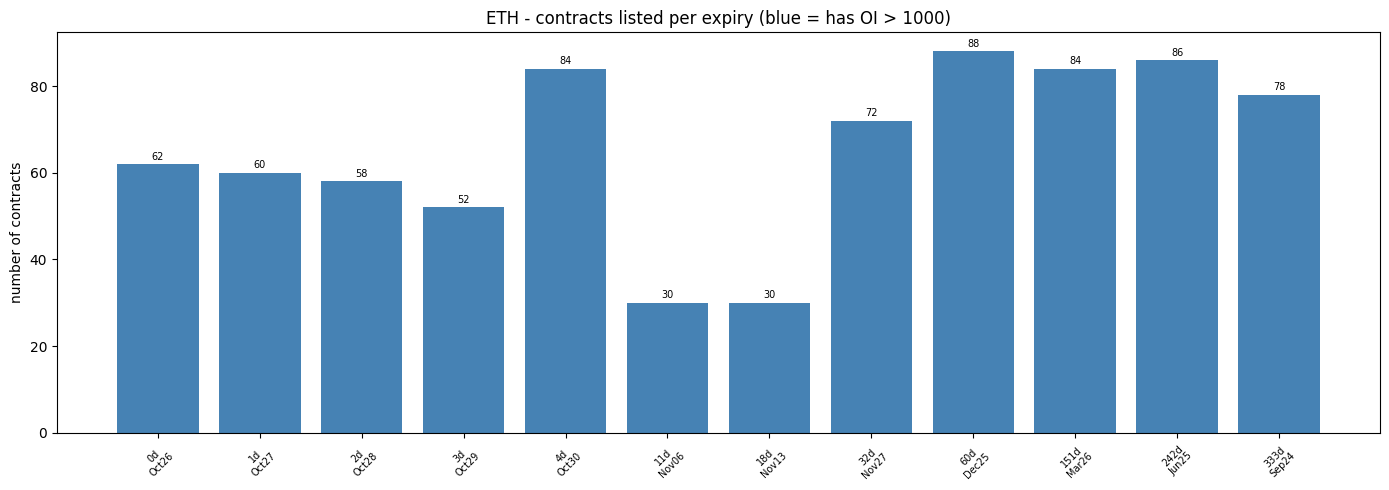

In [4]:
fig, ax = plt.subplots(figsize=(14, 5))
bars = ax.bar(range(len(expiries)), expiries['contracts'],
               color=['steelblue' if oi > 1000 else 'lightgray' for oi in expiries['total_oi']])
ax.set_xticks(range(len(expiries)))
ax.set_xticklabels([f'{d:.0f}d\n{e.strftime("%b%d")}' for d, e in zip(expiries['days'], expiries['expiry_dt'])],
                    rotation=45, fontsize=7)
ax.set_ylabel('number of contracts')
ax.set_title(f'ETH - contracts listed per expiry (blue = has OI > 1000)')

for b, v in zip(bars, expiries['contracts']):
    ax.text(b.get_x() + b.get_width()/2, v + 1, str(v), ha='center', fontsize=7)

plt.tight_layout(); plt.show()

## 4. Strikes per expiry

**What this tells you:** is the strike grid dense or sparse? Dense = granular position tuning. Sparse = jump between wide strikes.

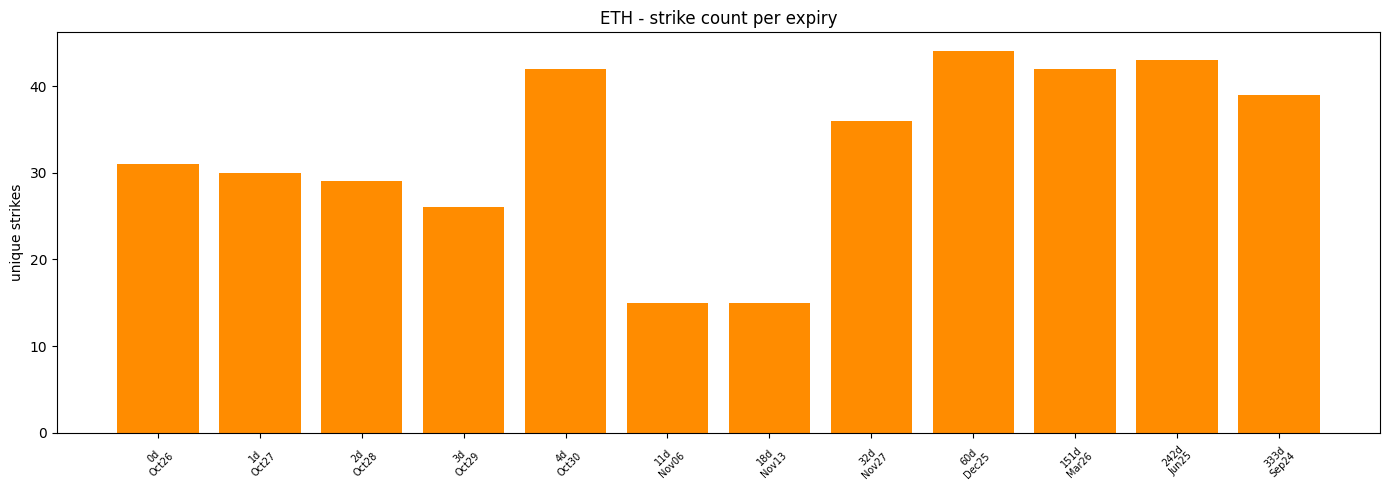

Median strikes per expiry: 34
Max strikes (one expiry): 44


In [5]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(range(len(expiries)), expiries['strikes'], color='darkorange')
ax.set_xticks(range(len(expiries)))
ax.set_xticklabels([f'{d:.0f}d\n{e.strftime("%b%d")}' for d, e in zip(expiries['days'], expiries['expiry_dt'])],
                    rotation=45, fontsize=7)
ax.set_ylabel('unique strikes')
ax.set_title('ETH - strike count per expiry')
plt.tight_layout(); plt.show()

print(f'Median strikes per expiry: {expiries["strikes"].median():.0f}')
print(f'Max strikes (one expiry): {expiries["strikes"].max()}')

## 5. Strike range per expiry

**What this tells you:** how far the strikes extend on each side of spot. Wide range = deep OTM protection is available. Narrow = only near-money contracts.

In [6]:
ranges = []
for _, row in expiries.iterrows():
    s = df[df.expiry == row['expiry']]
    ranges.append({
        'expiry': row['expiry_str'],
        'days': row['days'],
        'min_strike': s.strike.min(),
        'max_strike': s.strike.max(),
        'min_pct': (s.strike.min() - spot) / spot * 100,
        'max_pct': (s.strike.max() - spot) / spot * 100,
    })

rng = pd.DataFrame(ranges)
print(f'ETH spot: {spot:,.2f}\n')
print(rng.round(2).to_string(index=False))

KeyError: 'expiry'

## 6. OI by expiry

**What this tells you:** where the market actually has money committed. An expiry with 500 contracts but 0 OI is a listing, not a market.

In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))
x = np.arange(len(expiries))
w = 0.4
ax.bar(x - w/2, expiries['call_oi'], w, label='Calls OI', color='seagreen')
ax.bar(x + w/2, expiries['put_oi'],  w, label='Puts OI',  color='crimson')
ax.set_xticks(x)
ax.set_xticklabels([f'{d:.0f}d\n{e.strftime("%b%d")}' for d, e in zip(expiries['days'], expiries['expiry_dt'])],
                    rotation=45, fontsize=7)
ax.set_ylabel('open interest')
ax.set_title('ETH - OI by expiry (calls vs puts)')
ax.legend()
plt.tight_layout(); plt.show()

print(f'Total OI across all expiries: {expiries.total_oi.sum():,.0f}')
print(f'Nearest expiry OI:  {expiries.iloc[0].total_oi:,.0f}')
print(f'Highest-OI expiry:   {expiries.loc[expiries.total_oi.idxmax(), "expiry_str"]}  ({expiries.total_oi.max():,.0f})')

## 7. Volume today

**What this tells you:** what actually traded today. OI shows positions; volume shows activity. High volume + 0 OI = day traders. 0 volume + high OI = stuck positions.

In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))
bar_colors = ['seagreen' if v > 100 else 'lightgray' for v in expiries['volume']]
ax.bar(range(len(expiries)), expiries['volume'], color=bar_colors)
ax.set_xticks(range(len(expiries)))
ax.set_xticklabels([f'{d:.0f}d\n{e.strftime("%b%d")}' for d, e in zip(expiries['days'], expiries['expiry_dt'])],
                    rotation=45, fontsize=7)
ax.set_ylabel('contracts traded today')
ax.set_title('ETH - volume by expiry (green = actively traded)')
plt.tight_layout(); plt.show()

active = expiries[expiries.volume > 0]
print(f'Expiries with trades today: {len(active)} / {len(expiries)}')

## 8. Contracts with real liquidity

**The buyer filter:** how many contracts actually have an active market?

Criteria: bid > 0, ask > 0, spread < 20%, OI > 0, volume > 0

In [ ]:
liquid = df[(df.bid > 0) & (df.ask > 0) & (df.spread_pct < 0.20) & (df.oi > 0)].copy()
highly_liquid = liquid[liquid.volume > 0]

print(f'Total listed contracts: {len(df)}')
print(f'With two-sided quotes:  {len(df[(df.bid > 0) & (df.ask > 0)])}')
print(f'Liquid (spread < 20%): {len(liquid)}')
print(f'Traded today (vol>0):  {len(highly_liquid)}')
print()
print(f'Fraction tradeable: {len(highly_liquid)/len(df)*100:.1f}%')

## 9. Liquid contracts by expiry

**Where can you actually trade?** Not all expiries are created equal.

In [ ]:
liquid_by_exp = highly_liquid.groupby('expiry_dt').agg(
    contracts=('instrument', 'count'),
    days=('days', 'first'),
    avg_spread=('spread_pct', 'mean'),
    total_oi=('oi', 'sum'),
).reset_index().sort_values('expiry_dt')

liquid_by_exp['days'] = liquid_by_exp['days'].round(1)
liquid_by_exp['avg_spread_%'] = (liquid_by_exp['avg_spread'] * 100).round(2)
liquid_by_exp['expiry_str'] = liquid_by_exp['expiry_dt'].dt.strftime('%Y-%m-%d')

print('Tradeable contracts per expiry:')
print(liquid_by_exp[['expiry_str', 'days', 'contracts', 'avg_spread_%', 'total_oi']].to_string(index=False))

## 10. Strike coverage chart

**The full landscape:** every strike and expiry plotted as a point. Size of point = OI. Color = spread quality.

In [ ]:
fig, ax = plt.subplots(figsize=(14, 6))

for kind, color in [('C', 'seagreen'), ('P', 'crimson')]:
    s = df[(df.kind == kind) & (df.oi > 0)]
    sizes = s.oi / s.oi.max() * 200 + 10
    ax.scatter(s.days, s.strike, s=sizes, alpha=0.6,
               c=color, label=f'{kind} (calls)' if kind == 'C' else f'{kind} (puts)')

ax.axhline(spot, color='black', lw=2, ls='--', label=f'spot {spot:,.0f}')
ax.set_xlabel('days to expiry')
ax.set_ylabel('strike')
ax.set_title('ETH option universe - every contract with OI (size = OI)')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 11. Strike distribution (near the money)

**What this tells you:** near spot, how dense are the strikes? Dense = more granular choices for delta target.

In [ ]:
near = df[(df.strike > spot * 0.85) & (df.strike < spot * 1.15)]
strikes_per_expiry = near.groupby('expiry')['strike'].nunique()

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(range(len(strikes_per_expiry)), strikes_per_expiry.values, color='steelblue')
days_list = [(e - now_ms)/86_400_000 for e in strikes_per_expiry.index]
ax.set_xticks(range(len(strikes_per_expiry)))
ax.set_xticklabels([f'{d:.0f}d' for d in days_list], rotation=45, fontsize=8)
ax.set_ylabel('strikes within ±15% of spot')
ax.set_title('ETH - near-money strikes available per expiry')
plt.tight_layout(); plt.show()

## 12. Term structure of the chain

**What this tells you:** how the strike range grows with time. Longer expiries usually have wider strike grids.

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))

for kind, color in [('C', 'seagreen'), ('P', 'crimson')]:
    s = df[df.kind == kind]
    for exp, group in s.groupby('expiry_dt'):
        days = (exp - pd.Timestamp.now(tz='UTC')).total_seconds() / 86400
        min_pct = (group.strike.min() - spot) / spot * 100
        max_pct = (group.strike.max() - spot) / spot * 100
        ax.plot([days, days], [min_pct, max_pct], color=color, lw=2, alpha=0.5)
    ax.plot([], [], color=color, lw=2, label=f'{kind} strike range')

ax.axhline(0, color='black', ls='--', lw=1, alpha=0.5)
ax.set_xlabel('days to expiry')
ax.set_ylabel('strike % from spot')
ax.set_title('ETH - strike coverage grows with time')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 13. Expiry calendar view

**What this tells you:** all expiries on one timeline, colored by activity. Shows which expiration cycles are most important.

In [ ]:
fig, ax = plt.subplots(figsize=(14, 3))

for _, row in expiries.iterrows():
    color = 'seagreen' if row['total_oi'] > 10000 else ('steelblue' if row['total_oi'] > 1000 else 'lightgray')
    size = max(50, min(1000, row['total_oi'] / 200))
    ax.scatter(row['expiry_dt'], 0, s=size, color=color, alpha=0.7, edgecolor='black')
    ax.text(row['expiry_dt'], 0.3, f'{row["days"]:.0f}d',
            ha='center', fontsize=7, rotation=45)

ax.set_yticks([])
ax.set_xlabel('expiry date')
ax.set_title('ETH - expiry calendar (size = OI, color = activity)')
ax.grid(alpha=0.3, axis='x')
plt.tight_layout(); plt.show()

## 14. Tradeable contracts summary

**The final list:** contracts you can actually buy with tight spread and real OI.

In [ ]:
top_tradeable = highly_liquid.sort_values('oi', ascending=False).head(20)

top_tradeable['expiry_str'] = top_tradeable['expiry_dt'].dt.strftime('%d%b%y')
top_tradeable['strike'] = top_tradeable['strike'].astype(int)
top_tradeable['spread_%'] = (top_tradeable['spread_pct'] * 100).round(1)
top_tradeable['iv_%'] = (top_tradeable['iv_dec'] * 100).round(1)
top_tradeable['moneyness_%'] = ((top_tradeable['strike'] - spot) / spot * 100).round(1)

print(f'Top 20 tradeable ETH contracts by OI:')
print()
print(top_tradeable[['instrument', 'strike', 'kind', 'days', 'iv_%', 'spread_%', 'oi', 'volume', 'moneyness_%']].to_string(index=False))

## 15. Summary - the whole ETH option universe at a glance

In [ ]:
print('=' * 72)
print(f'ETH OPTION CHAIN - CURRENT STATE')
print('=' * 72)
print()
print(f'  Spot price            : ${spot:,.2f}')
print(f'  Total contracts       : {len(df):,}')
print(f'  Calls / Puts          : {(df.kind=="C").sum()} / {(df.kind=="P").sum()}')
print()
print(f'  EXPIRIES')
print(f'    Total               : {len(expiries)}')
print(f'    Nearest             : {expiries.days.min():.1f} days')
print(f'    Farthest            : {expiries.days.max():.1f} days ({expiries.days.max()/365:.1f}y)')
print(f'    Most active         : {expiries.loc[expiries.volume.idxmax(), "expiry_str"]}')
print()
print(f'  STRIKES')
print(f'    Total unique        : {df.strike.nunique()}')
    Range               : ${df.strike.min():,.0f} to ${df.strike.max():,.0f}')
print(f'    Near-money (-15%)   : {df[(df.strike > spot*0.85) & (df.strike < spot*1.15)].strike.nunique()}')
print()
print(f'  LIQUIDITY')
print(f'    Two-sided quotes    : {(df.bid > 0).sum() & (df.ask > 0).sum()}')
print(f'    Spread < 20%        : {len(liquid)}')
print(f'    Traded today        : {len(highly_liquid)}  ({len(highly_liquid)/len(df)*100:.0f}%)')
print()
print(f'  OI')
print(f'    Total OI            : {df.oi.sum():,.0f} contracts')
print(f'    Call OI             : {df[df.kind=="C"].oi.sum():,.0f}')
print(f'    Put OI              : {df[df.kind=="P"].oi.sum():,.0f}')
print(f'    PCR                 : {df[df.kind=="P"].oi.sum() / max(df[df.kind=="C"].oi.sum(), 1):.2f}')
print(f'    Largest expiry      : {expiries.loc[expiries.total_oi.idxmax(), "expiry_str"]}  ({expiries.total_oi.max():,.0f} contracts)')
print()
print(f'  BEST TRADEABLE WINDOW')
best = highly_liquid[(highly_liquid.days > 20) & (highly_liquid.days < 60)]
if len(best) > 0:
    best_oi = best.loc[best.oi.idxmax()]
    print(f'    Best contract       : {best_oi.instrument}')
    print(f'    Days to expiry      : {best_oi.days:.0f}')
    print(f'    OI                  : {best_oi.oi:,.0f}')
    print(f'    Spread              : {best_oi.spread_pct*100:.1f}%')
    print(f'    IV                  : {best_oi.iv_dec*100:.1f}%')
print()
print('=' * 72)

## 16. Interpretation guide

**How to read this notebook:**

| Metric | What it tells you |
|---|---|
| Number of expiries | How deep the chain is - more = more time choices |
| Farthest expiry | How far out you can hedge (years?) |
| Strikes per expiry | Granularity of strike choice |
| Strike range | How far OTM you can go |
| OI by expiry | Where real money is |
| Volume by expiry | What actually traded today |
| Liquid contracts | What you can buy (spread < 20%) |
| Traded today | What has real market making |

**Rule of thumb for buyers:**

- Trade only expiries with **OI > 1,000**
- Trade only contracts with **spread < 10%**
- Trade only contracts with **volume > 0 today**
- Prefer 20-60 days to expiry for balance of theta and delta
- Avoid the nearest 0-7 day expiries unless you have edge on short-term moves

## Notes

- All data is **live from Deribit**. No storage.
- Re-run to see updated state - prices and OI change hourly.
- **OI doesn't change fast** - the shape of the chain is stable over days.
- **Volume changes every hour** - that's where fresh information is.
- Combine with `pcr.ipynb`, `oi_analysis.ipynb`, `greeks_analysis.ipynb` for deeper analysis.
- This notebook answers '**what exists**', not '**what to trade**'.